### Cart-pole with custom static controller

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/alx87grd/minilink/blob/main/examples/teaching/courses/udes_gro501/cartpole_static_controller.ipynb)


**Importing Librairies**

This page uses the toolbox *minilink*.


In [63]:
# Local: minilink already installed. Colab: clone + path.
import sys

if "google.colab" in sys.modules:
    get_ipython().run_line_magic("matplotlib", "inline")
    get_ipython().system("git clone https://github.com/alx87grd/minilink")
    sys.path.insert(0, "/content/minilink")


fatal: destination path 'minilink' already exists and is not an empty directory.


In [64]:
import numpy as np
import scipy.linalg as linalg
import scipy.signal as signal
import matplotlib.pyplot as plt


# Defining the dynamics

Here we load a already defined class from the library including the dynamic equations of the cart-pole, which is a function of the form:

$\dot{x} = f(x,u)$


In [65]:
##############
# System
##############

from minilink import CartPole, System

sys  = CartPole()


The dynamical equations $\dot{x} = f(x,u)$ can be represented graphically by a vector field shown here:


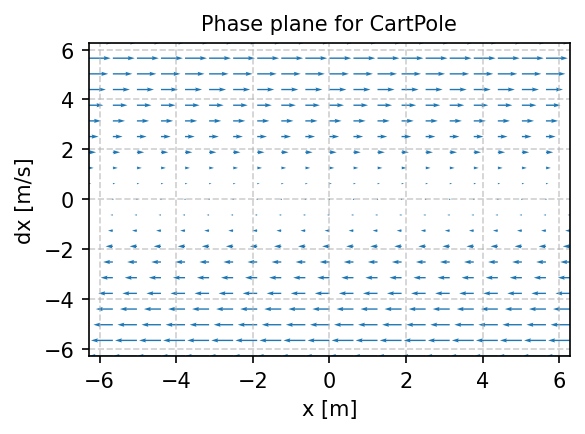

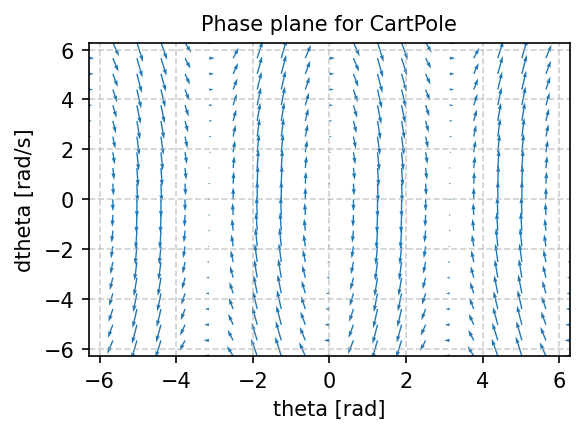

In [66]:
sys.plot_phase_plane(x_axis=0, y_axis=2) # Graphical illustration of the dynamic behavior in the phase plane
sys.plot_phase_plane(x_axis=1, y_axis=3)


Since the system has 4 states, the dynamics is actually a 4d vector field. Here we ploted 2 sub-planes of this higher dimension space.


### Showing the robot natural behavior with no controllers

Here we run a simulation of the system with no controllers:


In [67]:
# robot initial states [ joint 1 angle (rad),  joint 2 angle (rad), joint 1 velocity (rad/sec),  joint 1 velocity (rad/sec)]
sys.x0 = np.array([ 0.1, 0.1, 0.0, 0.0])

# run the simulation
sys.compute_trajectory( tf = 8 )

# Animate and display the simulation
sys.animate()



===               Time-Domain Simulation                  ===
system: 'CartPole'
n=4, m=1
x0: [0.1 0.1 0.  0. ]
interval: [0, 8]
n_pts=10001, dt=0.0008 (auto grid)
solver: 'scipy' (auto-selected)
backend='numpy'
solver_options: {'method': 'RK45', 'rtol': 0.0001, 'atol': 1e-07, 'use_jac': False}
------------------------------------------------------------
Running integration...
Completed in 0.022 seconds
------------------------------------------------------------
n_samples: 10001
x_final: [ 0.100706  0.084392 -0.011258  0.248553]
integration_stats: {'solver': 'scipy', 'mode': 'nominal', 'nfev': 470, 'njev': 0, 'nlu': 0, 'success': True, 'status': 0}


#Defining your control law


In [102]:
class CustomController( System ):

    ############################
    def __init__( self ):
        super().__init__()

        self.name = 'Custom Cart-pole Controller'

        self.add_input_port("y", dim=4)
        self.add_input_port("r", dim=1, nominal_value=0.0)
        self.add_output_port("u", dim=1, function=self.ctl, dependencies=("y",))

        m1 = 8.0  # kg
        m2 = 1.0  # kg
        g = 9.81  # N/kg
        l = 1.0   # m

        # Ordre des états : [x, theta, x_dot, theta_dot]
        # Colonnes        :  x  theta  x_dot  theta_dot
        A = np.array([
            [0, 0, 1, 0],
            [0, 0, 0, 1],
            [0, -m2*g/m1, 0, 0],             # Colonne 1 pour theta !
            [0, ((m1+m2)*g)/(m1*l), 0, 0]    # Colonne 1 pour theta !
        ])

        B = np.array([
            [0],
            [0],
            [1/m1],
            [-1/(m1*l)]
        ])

        C = np.array([
            [1, 0, 0, 0],
            [0, 1, 0, 0]
        ])

        D = np.array([
            [0],
            [0]
        ])

        # méthode placement de pôles pour synthétiser une matrice de gains
        poles_desires = np.array([-2.0, -2.5, -3.0, -3.5])

        result = signal.place_poles(A, B, poles_desires)
        self.K_poles = result.gain_matrix

        print(f"Gain à partir de la méthode de placement de pôles:\n{self.K_poles}\n")

        # Calcul LQR
        Q = np.diag([1.0, 10.0, 1.0, 1.0])  # Poids plus fort sur l'angle theta
        R = np.diag([0.5])

        S = linalg.solve_continuous_are(A, B, Q, R)
        R_inv = linalg.inv(R)
        self.K_lqr = R_inv @ B.T @ S

        print(f"Gain LQR K_lqr:\n{self.K_lqr}\n")

    #############################
    def ctl( self, x, u, t = 0, params=None ):

        y = self.get_port_values_from_u(u, "y")

        # Point d'équilibre haut : [x=0, theta=0, x_dot=0, theta_dot=0]
        x_err = y - np.array([0.0, 0.0, 0.0, 0.0])

        # u = - K * x_err  (NE PAS OUBLIER LE SIGNE MOINS !)
        u_cmd = (- self.K_lqr @ x_err).item()

        u_cmd = np.clip(u_cmd, -100.0, 100.0)

        return np.array([u_cmd])

ctl = CustomController()

Gain LQR K_lqr:
[[  -1.41421356 -210.35664413   -6.09871736  -63.95266182]]



## Simulation

Try to play with the initial conditions:


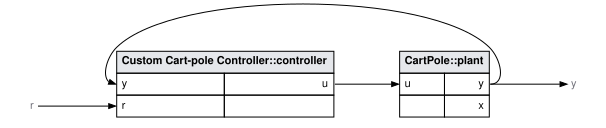

In [103]:
cl_sys = ctl @ sys

cl_sys.plot_diagram()

In [100]:
sys.x0[0] = 1.0
sys.x0[1] = 3.0

cl_sys.compute_trajectory( tf = 5.0 )


===               Time-Domain Simulation                  ===
system: 'Custom Cart-pole Controller @ CartPole'
n=4, m=1
x0: [1. 3. 0. 0.]
interval: [0, 5]
n_pts=10001, dt=0.0005 (auto grid)
solver: 'scipy' (auto-selected)
backend='numpy'
solver_options: {'method': 'RK45', 'rtol': 0.0001, 'atol': 1e-07, 'use_jac': False}
------------------------------------------------------------
Running integration...
Completed in 0.111 seconds
------------------------------------------------------------
n_samples: 10001
x_final: [800.570524  80.929709 383.411816  27.472722]
integration_stats: {'solver': 'scipy', 'mode': 'nominal', 'nfev': 908, 'njev': 0, 'nlu': 0, 'success': True, 'status': 0}


Trajectory, N=10001, t=0–5, x (4, 10001), u (1, 10001)

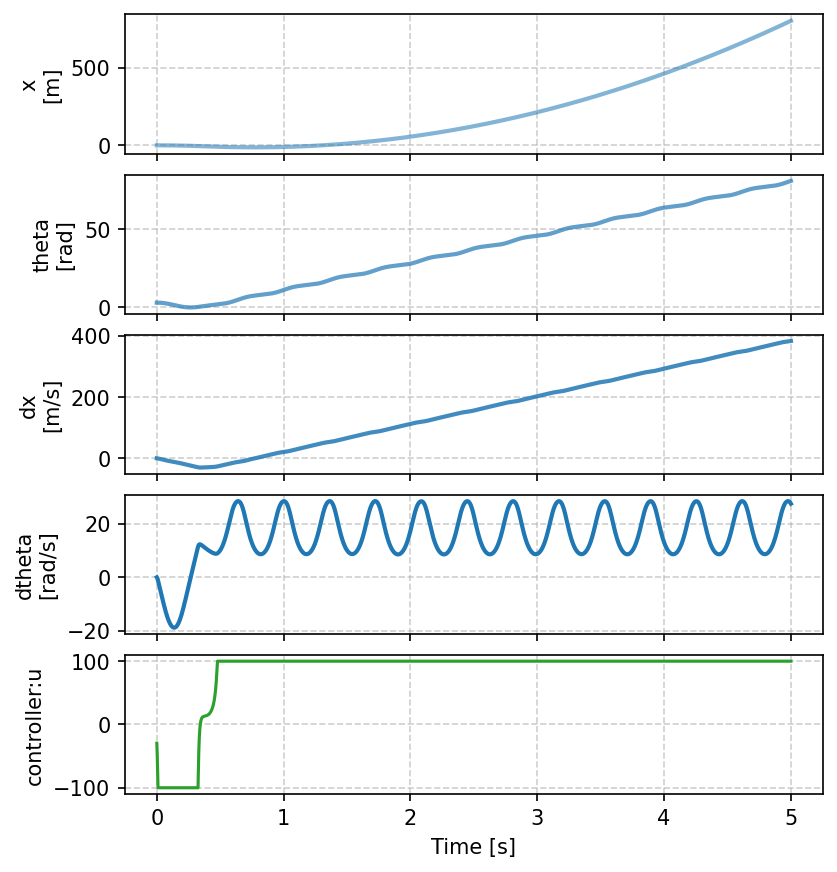

In [101]:
cl_sys.plot_trajectory()

In [93]:
# Animate and display the simulation
cl_sys.animate()
